In [1]:
import pandas as pd
from spacepy import pycdf
import numpy as np
from scipy.signal import butter, filtfilt
from scipy.linalg import eig
import matplotlib.pyplot as plt

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)
cdf

<CDF:
Epoch: CDF_TIME_TT2000 [1051008]
Epoch_state: CDF_TIME_TT2000 [2883]
label_b_bcs: CDF_CHAR*10 [4] NRV
label_b_dmpa: CDF_CHAR*10 [4] NRV
label_b_gse: CDF_CHAR*10 [4] NRV
label_b_gsm: CDF_CHAR*11 [4] NRV
label_r_gse: CDF_CHAR*10 [4] NRV
label_r_gsm: CDF_CHAR*10 [4] NRV
mms1_fgm_b_bcs_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_dmpa_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gse_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gsm_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_bdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_etemp_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_flag_srvy_l2: CDF_UINT4 [1051008]
mms1_fgm_hirange_srvy_l2: CDF_UINT1 [1051008]
mms1_fgm_mode_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_r_gse_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_r_gsm_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_rdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_stemp_srvy_l2: CDF_FLOAT [1051008]
represent_vec_tot: CDF_CHAR*1 [4] NRV
>

In [2]:
# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
B_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
B_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
B_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]

# Combine the data into a DataFrame
data = pd.DataFrame({
    'datetime': datetime,
    'B_x': B_x,
    'B_y': B_y,
    'B_z': B_z
}).set_index('datetime')
data

,B_x,B_y,B_z
datetime,,,
2015-10-28 00:00:10.963242,81.732841,-181.288544,445.587585
2015-10-28 00:00:11.088244,81.725143,-181.284271,445.566803
2015-10-28 00:00:11.213246,81.729637,-181.289795,445.544617
2015-10-28 00:00:11.338247,81.757286,-181.283447,445.520325
2015-10-28 00:00:11.463249,81.760918,-181.282104,445.496582
...,...,...,...
2015-10-29 00:00:11.490561,86.900932,-159.191711,395.277039
2015-10-29 00:00:11.615562,86.917961,-159.204590,395.254395
2015-10-29 00:00:11.740564,86.889862,-159.177521,395.238434


In [3]:
# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=4):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Calculate the sampling frequency
time_diff = np.diff(datetime.values.astype('datetime64[ns]').astype(float)) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut = 0.05  # Hz
highcut = 5    # Hz


In [4]:
# Apply the bandpass filter to each magnetic field component
data['B_x_f'] = bandpass_filter(data['B_x'].values, lowcut, highcut, sampling_freq)
data['B_y_f'] = bandpass_filter(data['B_y'].values, lowcut, highcut, sampling_freq)
data['B_z_f'] = bandpass_filter(data['B_z'].values, lowcut, highcut, sampling_freq)

# Select the filtered data within the specified time range
start_time = pd.Timestamp('2015-10-28 16:48:44')
end_time = pd.Timestamp('2015-10-28 16:55:12')
filtered_data = data.loc[start_time:end_time]

# Calculate mean values for the filtered components
m1, m2, m3 = filtered_data[['B_x_f', 'B_y_f', 'B_z_f']].mean()

# Calculate covariance matrix components
M11 = (filtered_data['B_x_f'] * filtered_data['B_x_f']).mean() - m1**2
M12 = (filtered_data['B_x_f'] * filtered_data['B_y_f']).mean() - m1*m2
M13 = (filtered_data['B_x_f'] * filtered_data['B_z_f']).mean() - m1*m3
M21 = M12
M22 = (filtered_data['B_y_f'] * filtered_data['B_y_f']).mean() - m2**2
M23 = (filtered_data['B_y_f'] * filtered_data['B_z_f']).mean() - m2*m3
M31 = M13
M32 = M23
M33 = (filtered_data['B_z_f'] * filtered_data['B_z_f']).mean() - m3**2


In [5]:
filtered_data

,B_x,B_y,B_z,B_x_f,B_y_f,B_z_f
datetime,,,,,,
2015-10-28 16:48:44.013072,15.078691,13.881310,46.145325,-0.007707,0.014641,-0.004620
2015-10-28 16:48:44.138073,15.064256,13.879420,46.143635,-0.018523,0.006526,-0.001281
2015-10-28 16:48:44.263075,15.082927,13.856483,46.150623,-0.004473,-0.007191,0.007827
2015-10-28 16:48:44.388077,15.083132,13.870223,46.145588,-0.008893,-0.002244,0.001410
2015-10-28 16:48:44.513078,15.073881,13.860817,46.128136,-0.013962,-0.002868,-0.007028
...,...,...,...,...,...,...
2015-10-28 16:55:11.393346,15.762014,14.646536,46.629063,0.095510,-0.108090,0.054526
2015-10-28 16:55:11.518348,15.755236,14.639022,46.622261,0.090149,-0.115397,0.041961
2015-10-28 16:55:11.643350,15.769809,14.666832,46.600563,0.095809,-0.088537,0.027710


In [6]:


# Create the covariance matrix
M = np.array([[M11, M12, M13],
              [M21, M22, M23],
              [M31, M32, M33]])

# Calculate eigenvalues and eigenvectors
vals, vecs = eig(M)
vals = np.real(vals)
vecs = np.real(vecs)

# Sort eigenvalues and corresponding eigenvectors
sorted_indices = np.argsort(vals)[::-1]
eig_vals = vals[sorted_indices]
eig_vecs = vecs[:, sorted_indices]

# Correct eigenvector orientations
X = np.cross(eig_vecs[:, 0], eig_vecs[:, 1])
Y = eig_vecs[:, 2]
if not np.array_equal(X, Y):
    eig_vecs[:, 1] *= -1
    eig_vecs[:, 2] *= -1

# Perform MVA using filtered data
mva_matrix = np.dot(filtered_data[['B_x_f', 'B_y_f', 'B_z_f']], eig_vecs)
filtered_data['B_L'] = mva_matrix[:, 0]
filtered_data['B_M'] = mva_matrix[:, 1]
filtered_data['B_N'] = mva_matrix[:, 2]
# filtered_data['B_total'] = np.sqrt(
#     filtered_data['B_L']**2 + filtered_data['B_M']**2 + filtered_data['B_N']**2
# )



/tmp/ipykernel_6290/3869080581.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['B_L'] = mva_matrix[:, 0]
/tmp/ipykernel_6290/3869080581.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['B_M'] = mva_matrix[:, 1]
/tmp/ipykernel_6290/3869080581.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/s

In [18]:
eig_vals

array([0.02648806, 0.01195724, 0.00143404])

In [19]:
eig_vals[1]/eig_vals[2]

np.float64(8.338135936123328)

In [7]:
filtered_data

,B_x,B_y,B_z,B_x_f,B_y_f,B_z_f,B_L,B_M,B_N
datetime,,,,,,,,,
2015-10-28 16:48:44.013072,15.078691,13.881310,46.145325,-0.007707,0.014641,-0.004620,-0.001266,-0.016875,0.002955
2015-10-28 16:48:44.138073,15.064256,13.879420,46.143635,-0.018523,0.006526,-0.001281,0.012298,-0.014510,0.005053
2015-10-28 16:48:44.263075,15.082927,13.856483,46.150623,-0.004473,-0.007191,0.007827,0.009583,0.004894,-0.004146
2015-10-28 16:48:44.388077,15.083132,13.870223,46.145588,-0.008893,-0.002244,0.001410,0.008851,-0.002065,0.001873
2015-10-28 16:48:44.513078,15.073881,13.860817,46.128136,-0.013962,-0.002868,-0.007028,0.010170,-0.004594,0.011315
...,...,...,...,...,...,...,...,...,...
2015-10-28 16:55:11.393346,15.762014,14.646536,46.629063,0.095510,-0.108090,0.054526,-0.015179,0.144350,-0.052073
2015-10-28 16:55:11.518348,15.755236,14.639022,46.622261,0.090149,-0.115397,0.041961,-0.012442,0.147218,-0.037097
2015-10-28 16:55:11.643350,15.769809,14.666832,46.600563,0.095809,-0.088537,0.027710,-0.033424,0.125032,-0.032186


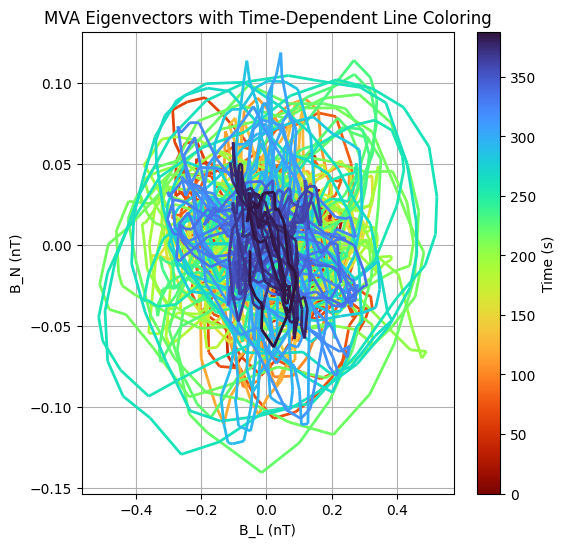

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Convert time to numeric for normalization
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()

# Prepare the data for the line segments
x = filtered_data['B_L'].values
y = filtered_data['B_N'].values

# Create segments for the line plot
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='turbo_r', norm=norm)
lc.set_array(time_numeric)  # Use the numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()  # Adjust axis limits to fit the line
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()


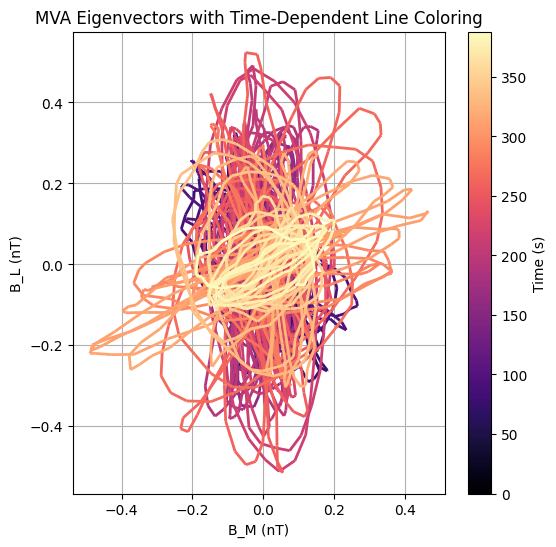

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Convert time to numeric for normalization
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()

# Prepare the data for the line segments
x = filtered_data['B_M'].values
y = filtered_data['B_L'].values

# Create segments for the line plot
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use the numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()  # Adjust axis limits to fit the line
ax.set_xlabel('B_M (nT)')
ax.set_ylabel('B_L (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()


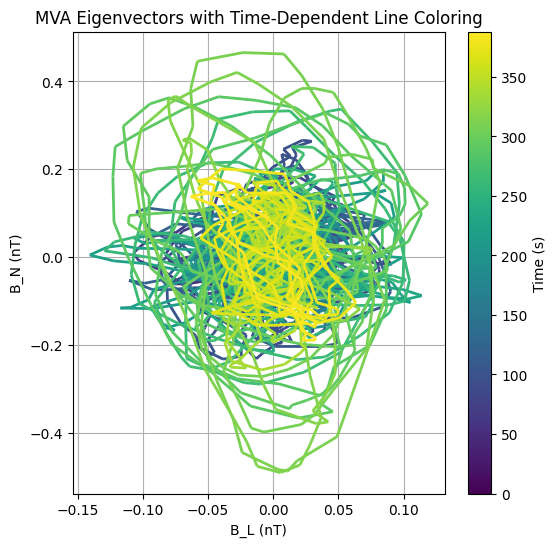

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Convert time to numeric for normalization
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()

# Prepare the data for the line segments
x = filtered_data['B_N'].values
y = filtered_data['B_M'].values

# Create segments for the line plot
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='viridis', norm=norm)
lc.set_array(time_numeric)  # Use the numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()  # Adjust axis limits to fit the line
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()


In [11]:
import plotly.subplots as sp
import plotly.graph_objects as go

# Create subplots
fig = sp.make_subplots(rows=2, cols=1, shared_xaxes=True, subplot_titles=(
    "Original Magnetic Field Components (GSE)", 
    "Magnetic Field Components in MVA Coordinate System"))

# First subplot: Original magnetic field components
fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_x'], mode='lines', name='B_x', line=dict(color='blue')), row=1, col=1)
fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_y'], mode='lines', name='B_y', line=dict(color='orange')), row=1, col=1)
fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_z'], mode='lines', name='B_z', line=dict(color='green')), row=1, col=1)

# Second subplot: MVA magnetic field components
fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_L'], mode='lines', name='B_L', line=dict(color='blue')), row=2, col=1)
fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_M'], mode='lines', name='B_M', line=dict(color='orange')), row=2, col=1)
fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_N'], mode='lines', name='B_N', line=dict(color='green')), row=2, col=1)

# Update layout for interactivity
fig.update_layout(
    title="Magnetic Field Data",
    xaxis_title="Time",
    yaxis_title="Magnetic Field (nT)",
    height=600
)

fig.show()


In [12]:
import numpy as np
from scipy.signal import find_peaks
import plotly.graph_objects as go
import plotly.subplots as sp

# Assume 'B_x' is the signal we want to analyze
signal = filtered_data['B_L'].values
time = filtered_data.index

# Find peaks (maxima) and troughs (minima)
peaks, _ = find_peaks(signal)
troughs, _ = find_peaks(-signal)

# Create subplots
fig = sp.make_subplots(rows=1, cols=1, subplot_titles=["Magnetic Field with Peaks and Troughs"])

# Plot the signal
fig.add_trace(go.Scatter(x=time, y=signal, mode='lines', name='B_L', line=dict(color='blue')))

# Add markers for peaks
fig.add_trace(go.Scatter(
    x=time[peaks], y=signal[peaks],
    mode='markers', name='Peaks', marker=dict(color='red', size=8)
))

# Add markers for troughs
fig.add_trace(go.Scatter(
    x=time[troughs], y=signal[troughs],
    mode='markers', name='Troughs', marker=dict(color='green', size=8)
))

# Update layout for interactivity
fig.update_layout(
    title="Magnetic Field with Wave Cycle Indicators",
    xaxis_title="Time",
    yaxis_title="Magnetic Field (nT)",
    height=600
)

fig.show()


In [13]:
# Number of cycles = minimum of peaks and troughs
total_cycles = min(len(peaks), len(troughs))
print(f"Total wave cycles: {total_cycles}")


Total wave cycles: 202


In [14]:
import numpy as np
from scipy.signal import find_peaks
import plotly.graph_objects as go
import plotly.subplots as sp

# Assume 'B_x' is the signal we want to analyze
signal = filtered_data['B_M'].values
time = filtered_data.index

# Find peaks (maxima) and troughs (minima)
peaks, _ = find_peaks(signal)
troughs, _ = find_peaks(-signal)

# Create subplots
fig = sp.make_subplots(rows=1, cols=1, subplot_titles=["Magnetic Field with Peaks and Troughs"])

# Plot the signal
fig.add_trace(go.Scatter(x=time, y=signal, mode='lines', name='B_M', line=dict(color='blue')))

# Add markers for peaks
fig.add_trace(go.Scatter(
    x=time[peaks], y=signal[peaks],
    mode='markers', name='Peaks', marker=dict(color='purple', size=8)
))

# Add markers for troughs
fig.add_trace(go.Scatter(
    x=time[troughs], y=signal[troughs],
    mode='markers', name='Troughs', marker=dict(color='green', size=8)
))

# Update layout for interactivity
fig.update_layout(
    title="Magnetic Field with Wave Cycle Indicators",
    xaxis_title="Time",
    yaxis_title="Magnetic Field (nT)",
    height=600
)

fig.show()


In [15]:
# Number of cycles = minimum of peaks and troughs
total_cycles = min(len(peaks), len(troughs))
print(f"Total wave cycles: {total_cycles}")


Total wave cycles: 295


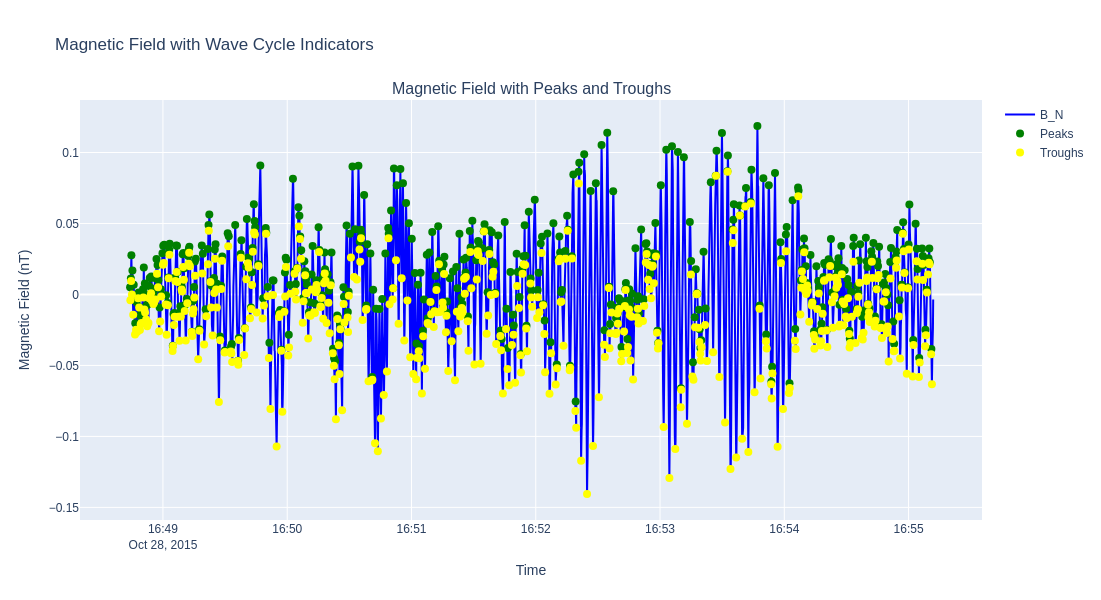

In [16]:
import numpy as np
from scipy.signal import find_peaks
import plotly.graph_objects as go
import plotly.subplots as sp

# Assume 'B_x' is the signal we want to analyze
signal = filtered_data['B_N'].values
time = filtered_data.index

# Find peaks (maxima) and troughs (minima)
peaks, _ = find_peaks(signal)
troughs, _ = find_peaks(-signal)

# Create subplots
fig = sp.make_subplots(rows=1, cols=1, subplot_titles=["Magnetic Field with Peaks and Troughs"])

# Plot the signal
fig.add_trace(go.Scatter(x=time, y=signal, mode='lines', name='B_N', line=dict(color='blue')))

# Add markers for peaks
fig.add_trace(go.Scatter(
    x=time[peaks], y=signal[peaks],
    mode='markers', name='Peaks', marker=dict(color='green', size=8)
))

# Add markers for troughs
fig.add_trace(go.Scatter(
    x=time[troughs], y=signal[troughs],
    mode='markers', name='Troughs', marker=dict(color='yellow', size=8)
))

# Update layout for interactivity
fig.update_layout(
    title="Magnetic Field with Wave Cycle Indicators",
    xaxis_title="Time",
    yaxis_title="Magnetic Field (nT)",
    height=600
)

fig.show()


In [17]:
# Number of cycles = minimum of peaks and troughs
total_cycles = min(len(peaks), len(troughs))
print(f"Total wave cycles: {total_cycles}")


Total wave cycles: 502
